# 02 Logistic Regression


## Imports and dataset


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve,
    roc_auc_score
)

In [ ]:
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent

data_path = project_root / 'data' / 'raw' / 'PS_20174392719_1491204439457_log.csv'
if not data_path.is_file():
    raise FileNotFoundError(f'Download the PaySim CSV and place it at {data_path}')

df = pd.read_csv(data_path)


In [4]:
df[['step', 'type', 'amount', 'isFraud']]

,step,type,amount,isFraud
0,1,PAYMENT,9839.64,0
1,1,PAYMENT,1864.28,0
2,1,TRANSFER,181.00,1
3,1,CASH_OUT,181.00,1
4,1,PAYMENT,11668.14,0
...,...,...,...,...
6362615,743,CASH_OUT,339682.13,1
6362616,743,TRANSFER,6311409.28,1
6362617,743,CASH_OUT,6311409.28,1
6362618,743,TRANSFER,850002.52,1


## Chronological train, validation, and test split


In [5]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

In [6]:
df['step'].iloc[train_end]

np.int64(323)

In [7]:
df['step'].iloc[val_end]

np.int64(378)

In [8]:
train_df = df[df['step'] < 323].copy()

val_df = df[(df['step'] >= 323) & (df['step'] < 378)].copy()

test_df = df[df['step'] >= 378].copy()

In [9]:
train_df.shape[0]

4433703

In [10]:
(train_df.shape[0] / df.shape[0]) * 100

69.68360518151327

In [11]:
val_df.shape[0]

973173

In [12]:
(val_df.shape[0] / df.shape[0]) * 100

15.295161427210804

In [13]:
test_df.shape[0]

955744

In [14]:
(test_df.shape[0] / df.shape[0]) * 100

15.02123339127592

In [15]:
train_df.isFraud.value_counts()

,count
isFraud,
0,4430070
1,3633


In [16]:
train_df.isFraud.mean() * 100

np.float64(0.08194053593576295)

In [17]:
val_df.isFraud.value_counts()

,count
isFraud,
0,972603
1,570


In [18]:
val_df.isFraud.mean() * 100

np.float64(0.05857129205187567)

In [19]:
test_df.isFraud.value_counts()

,count
isFraud,
0,951734
1,4010


In [20]:
test_df.isFraud.mean() * 100

np.float64(0.4195684199953125)

In [21]:
train_df.step.max() < val_df.step.min()

True

In [22]:
val_df.step.max() < test_df.step.min()

True

## Features and preprocessing


In [23]:
features = ['step', 'type', 'amount']
target = 'isFraud'

In [24]:
X_train, X_val, X_test = train_df[features], val_df[features], test_df[features]
y_train, y_val, y_test = train_df[target], val_df[target], test_df[target]

In [25]:
numeric_features = ['step', 'amount']
categorical_features = ['type']

preprocessor = ColumnTransformer(
transformers=[('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)]
)
preprocessor

ColumnTransformer(transformers=[('num', StandardScaler(), ['step', 'amount']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['type'])])

## Unweighted Logistic Regression


In [26]:
model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['step', 'amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [27]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['step', 'amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [28]:
model.named_steps['classifier'].n_iter_

array([19], dtype=int32)

In [29]:
y_val_pred = model.predict(X_val)
y_val_proba = model.predict_proba(X_val)[:, 1]

In [30]:
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

print("Average Precision:", average_precision_score(y_val, y_val_proba))

print("ROC-AUC:", roc_auc_score(y_val, y_val_proba))

Confusion Matrix:
[[972603      0]
 [   570      0]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    972603
           1       0.00      0.00      0.00       570

    accuracy                           1.00    973173
   macro avg       0.50      0.50      0.50    973173
weighted avg       1.00      1.00      1.00    973173

Average Precision: 0.003143772231183661
ROC-AUC: 0.8803146560709729


In [31]:
pd.Series(y_val_proba).describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999])

,0
count,973173.000000
mean,0.000687
std,0.001191
min,0.000012
50%,0.000021
90%,0.000977
95%,0.003692
99%,0.004516
99.9%,0.009128
max,0.116265


In [32]:
prob_df = pd.DataFrame({
    'actual': y_val.to_numpy(),
    'fraud_probability': y_val_proba
})

prob_df.groupby('actual')['fraud_probability'].describe(percentiles=[0.5, 0.9, 0.99])

,count,mean,std,min,50%,90%,99%,max
actual,,,,,,,,
0,972603.0,0.000686,0.001190,0.000012,0.000021,0.000977,0.004513,0.116265
1,570.0,0.002572,0.001707,0.000889,0.002859,0.004108,0.008514,0.008828


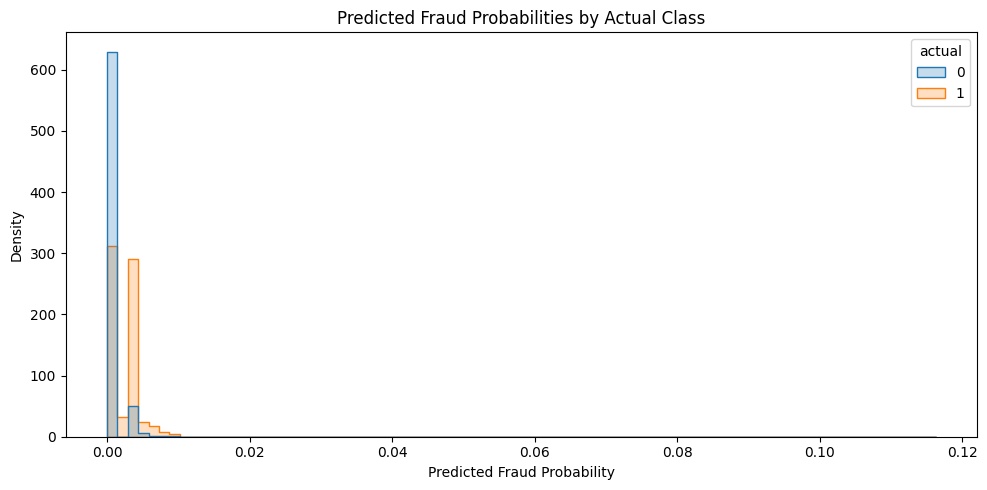

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=prob_df,
    x='fraud_probability',
    hue='actual',
    bins=80,
    stat='density',
    common_norm=False,
    element='step'
)

plt.title('Predicted Fraud Probabilities by Actual Class')
plt.xlabel('Predicted Fraud Probability')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

## Classification thresholds


In [34]:
thresholds = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1]

for threshold in thresholds:
    y_pred = (y_val_proba >= threshold).astype(int)

    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)

    print(
        f"Threshold: {threshold:.3f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.001 | Precision: 0.0045 | Recall: 0.6632 | F1: 0.0089
Threshold: 0.005 | Precision: 0.0055 | Recall: 0.0579 | F1: 0.0100
Threshold: 0.010 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000
Threshold: 0.020 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000
Threshold: 0.050 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000
Threshold: 0.100 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000


In [35]:
thresholds = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1]

for threshold in thresholds:
    y_pred = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    print(
        f"Threshold: {threshold:.3f} | "
        f"TP: {tp} | FP: {fp} | "
        f"FN: {fn} | TN: {tn}"
    )

Threshold: 0.001 | TP: 378 | FP: 83638 | FN: 192 | TN: 888965
Threshold: 0.005 | TP: 33 | FP: 5976 | FN: 537 | TN: 966627
Threshold: 0.010 | TP: 0 | FP: 404 | FN: 570 | TN: 972199
Threshold: 0.020 | TP: 0 | FP: 88 | FN: 570 | TN: 972515
Threshold: 0.050 | TP: 0 | FP: 9 | FN: 570 | TN: 972594
Threshold: 0.100 | TP: 0 | FP: 1 | FN: 570 | TN: 972602


## Class-weighted Logistic Regression


In [36]:
weighted_model = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))])

In [37]:
weighted_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['step', 'amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [60]:
weighted_model.named_steps['classifier'].n_iter_

array([20], dtype=int32)

In [39]:
y_val_pred = weighted_model.predict(X_val)
y_val_proba = weighted_model.predict_proba(X_val)[:, 1]

In [42]:
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

print("Average Precision:", average_precision_score(y_val, y_val_proba))

print("ROC-AUC:", roc_auc_score(y_val, y_val_proba))

Confusion Matrix:
[[881195  91408]
 [   159    411]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95    972603
           1       0.00      0.72      0.01       570

    accuracy                           0.91    973173
   macro avg       0.50      0.81      0.48    973173
weighted avg       1.00      0.91      0.95    973173

Average Precision: 0.004307626868411828
ROC-AUC: 0.890561001512833


In [43]:
unweighted_proba = model.predict_proba(X_val)[:, 1]
weighted_proba = weighted_model.predict_proba(X_val)[:, 1]

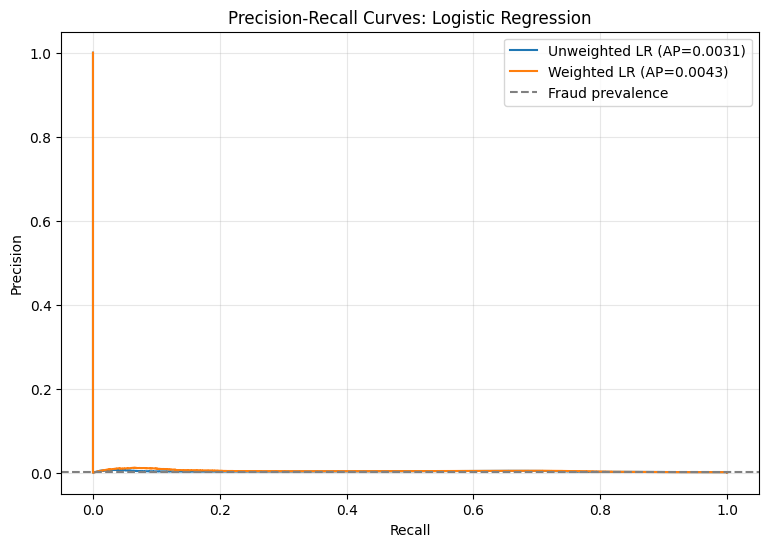

In [46]:
p1, r1, _ = precision_recall_curve(y_val, unweighted_proba)
p2, r2, _ = precision_recall_curve(y_val, weighted_proba)

ap1 = average_precision_score(y_val, unweighted_proba)
ap2 = average_precision_score(y_val, weighted_proba)

plt.figure(figsize=(9, 6))

plt.plot(r1, p1, label=f'Unweighted LR (AP={ap1:.4f})')
plt.plot(r2, p2, label=f'Weighted LR (AP={ap2:.4f})')

plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    color='gray',
    label='Fraud prevalence'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves: Logistic Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

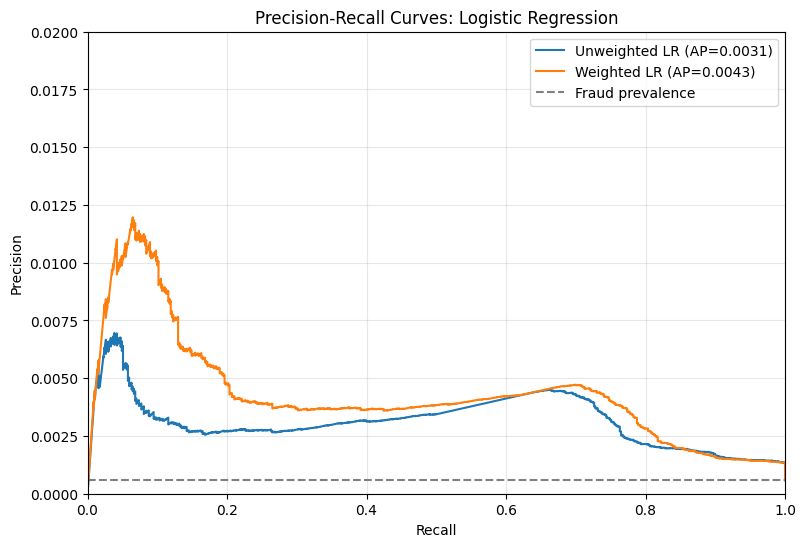

In [47]:
p1, r1, _ = precision_recall_curve(y_val, unweighted_proba)
p2, r2, _ = precision_recall_curve(y_val, weighted_proba)

ap1 = average_precision_score(y_val, unweighted_proba)
ap2 = average_precision_score(y_val, weighted_proba)

plt.figure(figsize=(9, 6))

plt.plot(r1, p1, label=f'Unweighted LR (AP={ap1:.4f})')
plt.plot(r2, p2, label=f'Weighted LR (AP={ap2:.4f})')

plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    color='gray',
    label='Fraud prevalence'
)

plt.xlim(0, 1)
plt.ylim(0, 0.02)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves: Logistic Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Log-transformed amount experiment


In [64]:
X_train_log = X_train.copy()
X_val_log = X_val.copy()
X_train_log['amount'] = np.log1p(X_train_log['amount'])
X_val_log['amount'] = np.log1p(X_val_log['amount'])

In [65]:
log_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [66]:
log_model.fit(X_train_log, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['step', 'amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [67]:
log_model.named_steps['classifier'].n_iter_

array([11], dtype=int32)

In [71]:
log_val_pred = log_model.predict(X_val_log)
log_val_proba = log_model.predict_proba(X_val_log)[:, 1]

In [73]:
print("Confusion Matrix:")
print(confusion_matrix(y_val, log_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, log_val_pred, zero_division=0))

print("Average Precision:",
      average_precision_score(y_val, log_val_proba))

print("ROC-AUC:",
      roc_auc_score(y_val, log_val_proba))

Confusion Matrix:
[[972603      0]
 [   570      0]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    972603
           1       0.00      0.00      0.00       570

    accuracy                           1.00    973173
   macro avg       0.50      0.50      0.50    973173
weighted avg       1.00      1.00      1.00    973173

Average Precision: 0.0032586528520396315
ROC-AUC: 0.8679288556296143
